# Most Streamed Spotify Songs 2023

- track_name: Numele melodiei
- artist(s)name: Numele artistului(ilor) melodiei
- artist_count: Numărul de artiști care contribuie la melodie
- released_year: Anul în care melodia a fost lansată
- released_month: Luna în care melodia a fost lansată
- released_day: Ziua lunii în care melodia a fost lansată
- in_spotify_playlists: Numărul de liste de redare Spotify în care melodia este inclusă
- streams: Numărul total de audiții pe Spotify
- in_apple_playlists: Numărul de liste de redare Apple Music în care melodia este inclusă
- in_apple_charts: Prezența și poziția melodiei în clasamentele Apple Music
- in_deezer_playlists: Numărul de liste de redare Deezer în care melodia este inclusă
- in_deezer_charts: Prezența și poziția melodiei în clasamentele Deezer
- in_shazam_charts: Prezența și poziția melodiei în clasamentele Shazam
- bpm: Bătăi pe minut, o măsură a tempoului melodiei
- key: Tonalitatea melodiei
- mode: Modul melodiei (major sau minor)
- danceability%: Procentaj care indică cât de potrivită este melodia pentru dans
- valence_%: Pozitivitatea conținutului muzical al melodiei
- energy_%: Nivelul de energie perceput al melodiei
- acousticness_%: Cantitatea de sunet acustic din melodie
- instrumentalness_%: Cantitatea de conținut instrumental din melodie
- liveness_%: Prezența elementelor de interpretare live
- speechiness_%: Cantitatea de cuvinte vorbite în melodie

Vechea variabila tinta:
- in_spotify_charts: Prezența și poziția melodiei în clasamentele Spotify - MODIFICAȚI coloana asta astfel încăt să fie 0 dacă nu e prezentă în topuri spotify, 1 dacă e prezentă dar nu în top5, 2 dacă e în top 5.

Am modificat variabila tinta si acum este:
- in_spotify_charts_target: 0 daca nu apare in topuri Spotify, 1 daca apare in topuri Spotify

#  I. Analiza exploratorie a datelor

## Importul bibliotecilor

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

# Setare pentru afișare mai clară a graficelor și datelor
sns.set_theme(style="whitegrid")
import warnings
warnings.filterwarnings('ignore')

## Încărcarea datelor și verificarea cantitativă de bază

In [2]:
# Citirea setului de date Spotify 2023
data_path = '../data/raw/spotify-2023.csv'

try:
    df = pd.read_csv(data_path, encoding='latin-1')
except FileNotFoundError:
    data_path = 'data/raw/spotify-2023.csv'
    df = pd.read_csv(data_path, encoding='latin-1')

print(f"Setul de date a fost încărcat cu succes!")
print(f"Dimensiunea setului de date: {df.shape[0]} rânduri și {df.shape[1]} coloane.")

# O scurtă privire asupra primelor rânduri
display(df.head(3))

Setul de date a fost încărcat cu succes!
Dimensiunea setului de date: 953 rânduri și 24 coloane.


,track_name,artist(s)_name,artist_count,released_year,released_month,released_day,in_spotify_playlists,in_spotify_charts,streams,in_apple_playlists,...,bpm,key,mode,danceability_%,valence_%,energy_%,acousticness_%,instrumentalness_%,liveness_%,speechiness_%
0,Seven (feat. Latto) (Explicit Ver.),"Latto, Jung Kook",2,2023,7,14,553,147,141381703,43,...,125,B,Major,80,89,83,31,0,8,4
1,LALA,Myke Towers,1,2023,3,23,1474,48,133716286,48,...,92,C#,Major,71,61,74,7,0,10,4
2,vampire,Olivia Rodrigo,1,2023,6,30,1397,113,140003974,94,...,138,F,Major,51,32,53,17,0,31,6


## Analiza valorilor lipsă

In [3]:
# Calculul valorilor lipsă la nivel de coloană
missing_data = pd.DataFrame({
    'Nume coloana': df.columns,
    'Valori lipsa (nr)': df.isnull().sum().values,
    'Procent valori lipsa (%)': (df.isnull().sum() / len(df) * 100).round(2)
})

# Filtrăm doar coloanele care au valori lipsă pentru a fi tabelul mai facil de citit
missing_data_filtered = missing_data[missing_data['Valori lipsa (nr)'] > 0].reset_index(drop=True)

print("Coloanele care conțin valori lipsă:")
display(missing_data_filtered)

Coloanele care conțin valori lipsă:


,Nume coloana,Valori lipsa (nr),Procent valori lipsa (%)
0,in_shazam_charts,50,5.25
1,key,95,9.97


## Curățarea și transformarea coloanelor cu probleme

In [4]:
# 1. Curățarea coloanei 'in_shazam_charts'
df['in_shazam_charts'] = df['in_shazam_charts'].fillna(0)
df['in_shazam_charts'] = df['in_shazam_charts'].astype(str).str.replace(',', '', regex=True)
df['in_shazam_charts'] = pd.to_numeric(df['in_shazam_charts'], errors='coerce').fillna(0).astype('int64')

# 2. Curățarea coloanei 'in_deezer_playlists'
df['in_deezer_playlists'] = df['in_deezer_playlists'].astype(str).str.replace(',', '', regex=True)
df['in_deezer_playlists'] = pd.to_numeric(df['in_deezer_playlists'], errors='coerce').fillna(0).astype('int64')

# 3. Maparea coloanei 'key' (note muzicale în valori numerice)
pitch_class = {
    'C': 0, 'C#': 1, 'D': 2, 'D#': 3, 'E': 4, 'F': 5,
    'F#': 6, 'G': 7, 'G#': 8, 'A': 9, 'A#': 10, 'B': 11
}
df['key'] = df['key'].map(pitch_class)
df['key'] = df['key'].fillna(-1).astype('int64')

# 4. Curățarea coloanei 'streams' (eliminarea valorilor non-numerice dacă există)
df['streams'] = df['streams'].astype(str).str.replace(',', '', regex=True)
df['streams'] = pd.to_numeric(df['streams'], errors='coerce')

# Dacă există valori nule apărute la streams, le putem elimina sau imputa
df = df.dropna(subset=['streams']).reset_index(drop=True)
df['streams'] = df['streams'].astype('int64')

# 5. Crearea variabilei țintă binară ('in_spotify_charts_target'): 0 dacă nu apare în topuri, 1 dacă apare
df['in_spotify_charts_target'] = df['in_spotify_charts'].apply(lambda x: 0 if x == 0 else 1)

print("Distribuția noii variabile țintă:")
print(df['in_spotify_charts_target'].value_counts())

Distribuția noii variabile țintă:
in_spotify_charts_target
1    548
0    404
Name: count, dtype: int64


## Distribuția calitativă și temporală

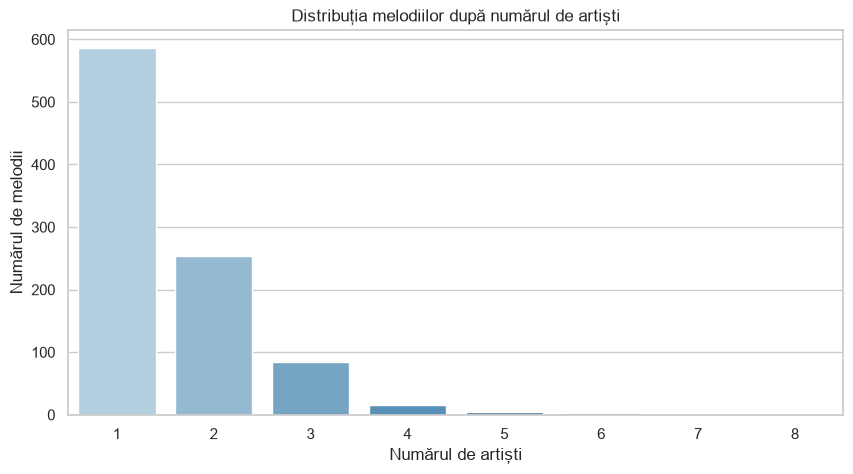

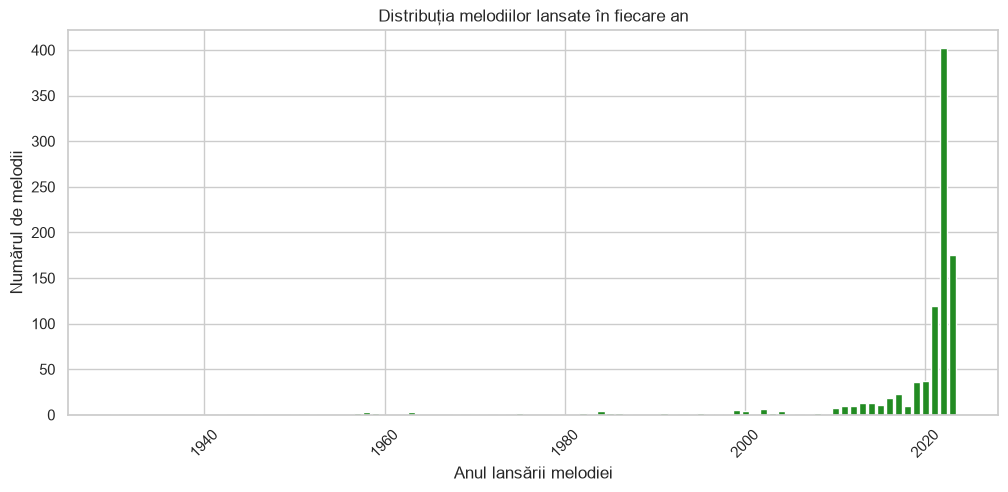

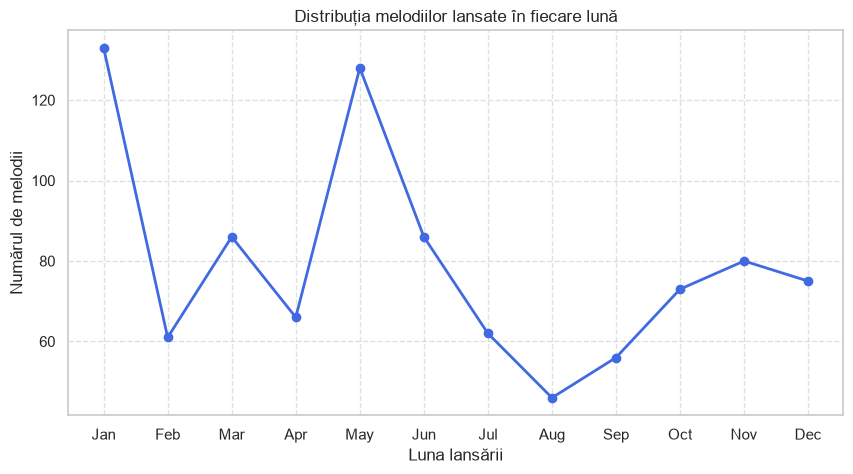

In [5]:
import calendar

# 1. Distribuția în funcție de numărul de artiști
plt.figure(figsize=(10, 5))
sns.countplot(x='artist_count', data=df, palette='Blues_d', hue='artist_count', legend=False)
plt.xlabel('Numărul de artiști')
plt.ylabel('Numărul de melodii')
plt.title('Distribuția melodiilor după numărul de artiști')
plt.show()

# 2. Distribuția în funcție de anul lansării
melodii_pe_an = df['released_year'].value_counts().sort_index()
plt.figure(figsize=(12, 5))
plt.bar(melodii_pe_an.index, melodii_pe_an.values, color='forestgreen')
plt.xlabel('Anul lansării melodiei')
plt.ylabel('Numărul de melodii')
plt.title('Distribuția melodiilor lansate în fiecare an')
plt.xticks(rotation=45)
plt.show()

# 3. Distribuția în funcție de luna lansării
numar_melodii_pe_luna = df['released_month'].value_counts().sort_index()
abrevierea_lunii = [calendar.month_abbr[i] for i in range(1, 13)]

plt.figure(figsize=(10, 5))
plt.plot(abrevierea_lunii, numar_melodii_pe_luna.values, color='royalblue', marker='o', linewidth=2, markersize=6)
plt.xlabel('Luna lansării')
plt.ylabel('Numărul de melodii')
plt.title('Distribuția melodiilor lansate în fiecare lună')
plt.grid(True, linestyle='--', alpha=0.6)
plt.show()

###  Analiză: Distribuția melodiilor după numărul de artiști
* **Dominanța pieselor solo:** Majoritatea covârșitoare a pieselor din topuri sunt interpretate de un singur artist (aproape 600 de melodii), urmate de duete.
* **Impactul colaborărilor multiple:** Colaborările extinse (cu 3 sau mai mulți artiști) devin din ce în ce mai rare, sugerând că succesul comercial pe Spotify nu depinde de o echipă numeroasă de colaboratori.

###  Analiză: Distribuția melodiilor lansate în fiecare an
* **Concentrare temporală recentă și efectul pandemic (2020–2023):** Setul de date reflectă predominant tendințele muzicale actuale, înregistrând o creștere explozivă a pieselor virale în ultimii ani, cu vârfuri masive în perioada 2020–2023. Această creștere bruscă poate fi corelată direct cu contextul global generat de pandamia de COVID-19 (perioadele de izolare acasă), care a accelerat exponențial consumul de divertisment digital și ascultările pe platformele de streaming precum Spotify.
* **Piese clasice longevive:** Anii anteriori (deceniile trecute) apar doar sporadic, reprezentând acele melodii excepționale care și-au menținut popularitatea în timp pe platformă.

###  Analiză: Distribuția melodiilor lansate în fiecare lună
* **Caracterul sezonier al lansărilor:** Se remarcă două momente principale de intensitate în lansări: un vârf pronunțat la începutul anului (ianuarie) și un altul important în primăvară (mai). Vârful din mai reprezintă o mișcare calculată a industriei pentru a lansa piese care să devină hituri pe durata sezonului cald, anticipând vacanțele de vară, festivalurile și petrecerile.
* **Perioade de activitate scăzută (Efectul vacanțelor):** Lunile de vară și începutul toamnei (în special august și septembrie) înregistrează cel mai mic volum de piese noi. Acest lucru se explică prin faptul că perioada estivală coincide cu concediile publicului larg și o scădere a atenției media, determinând artiștii să amâne lansările majore pentru sezoanele mai active.

## Distribuția variabilelor numerice (Histograme)

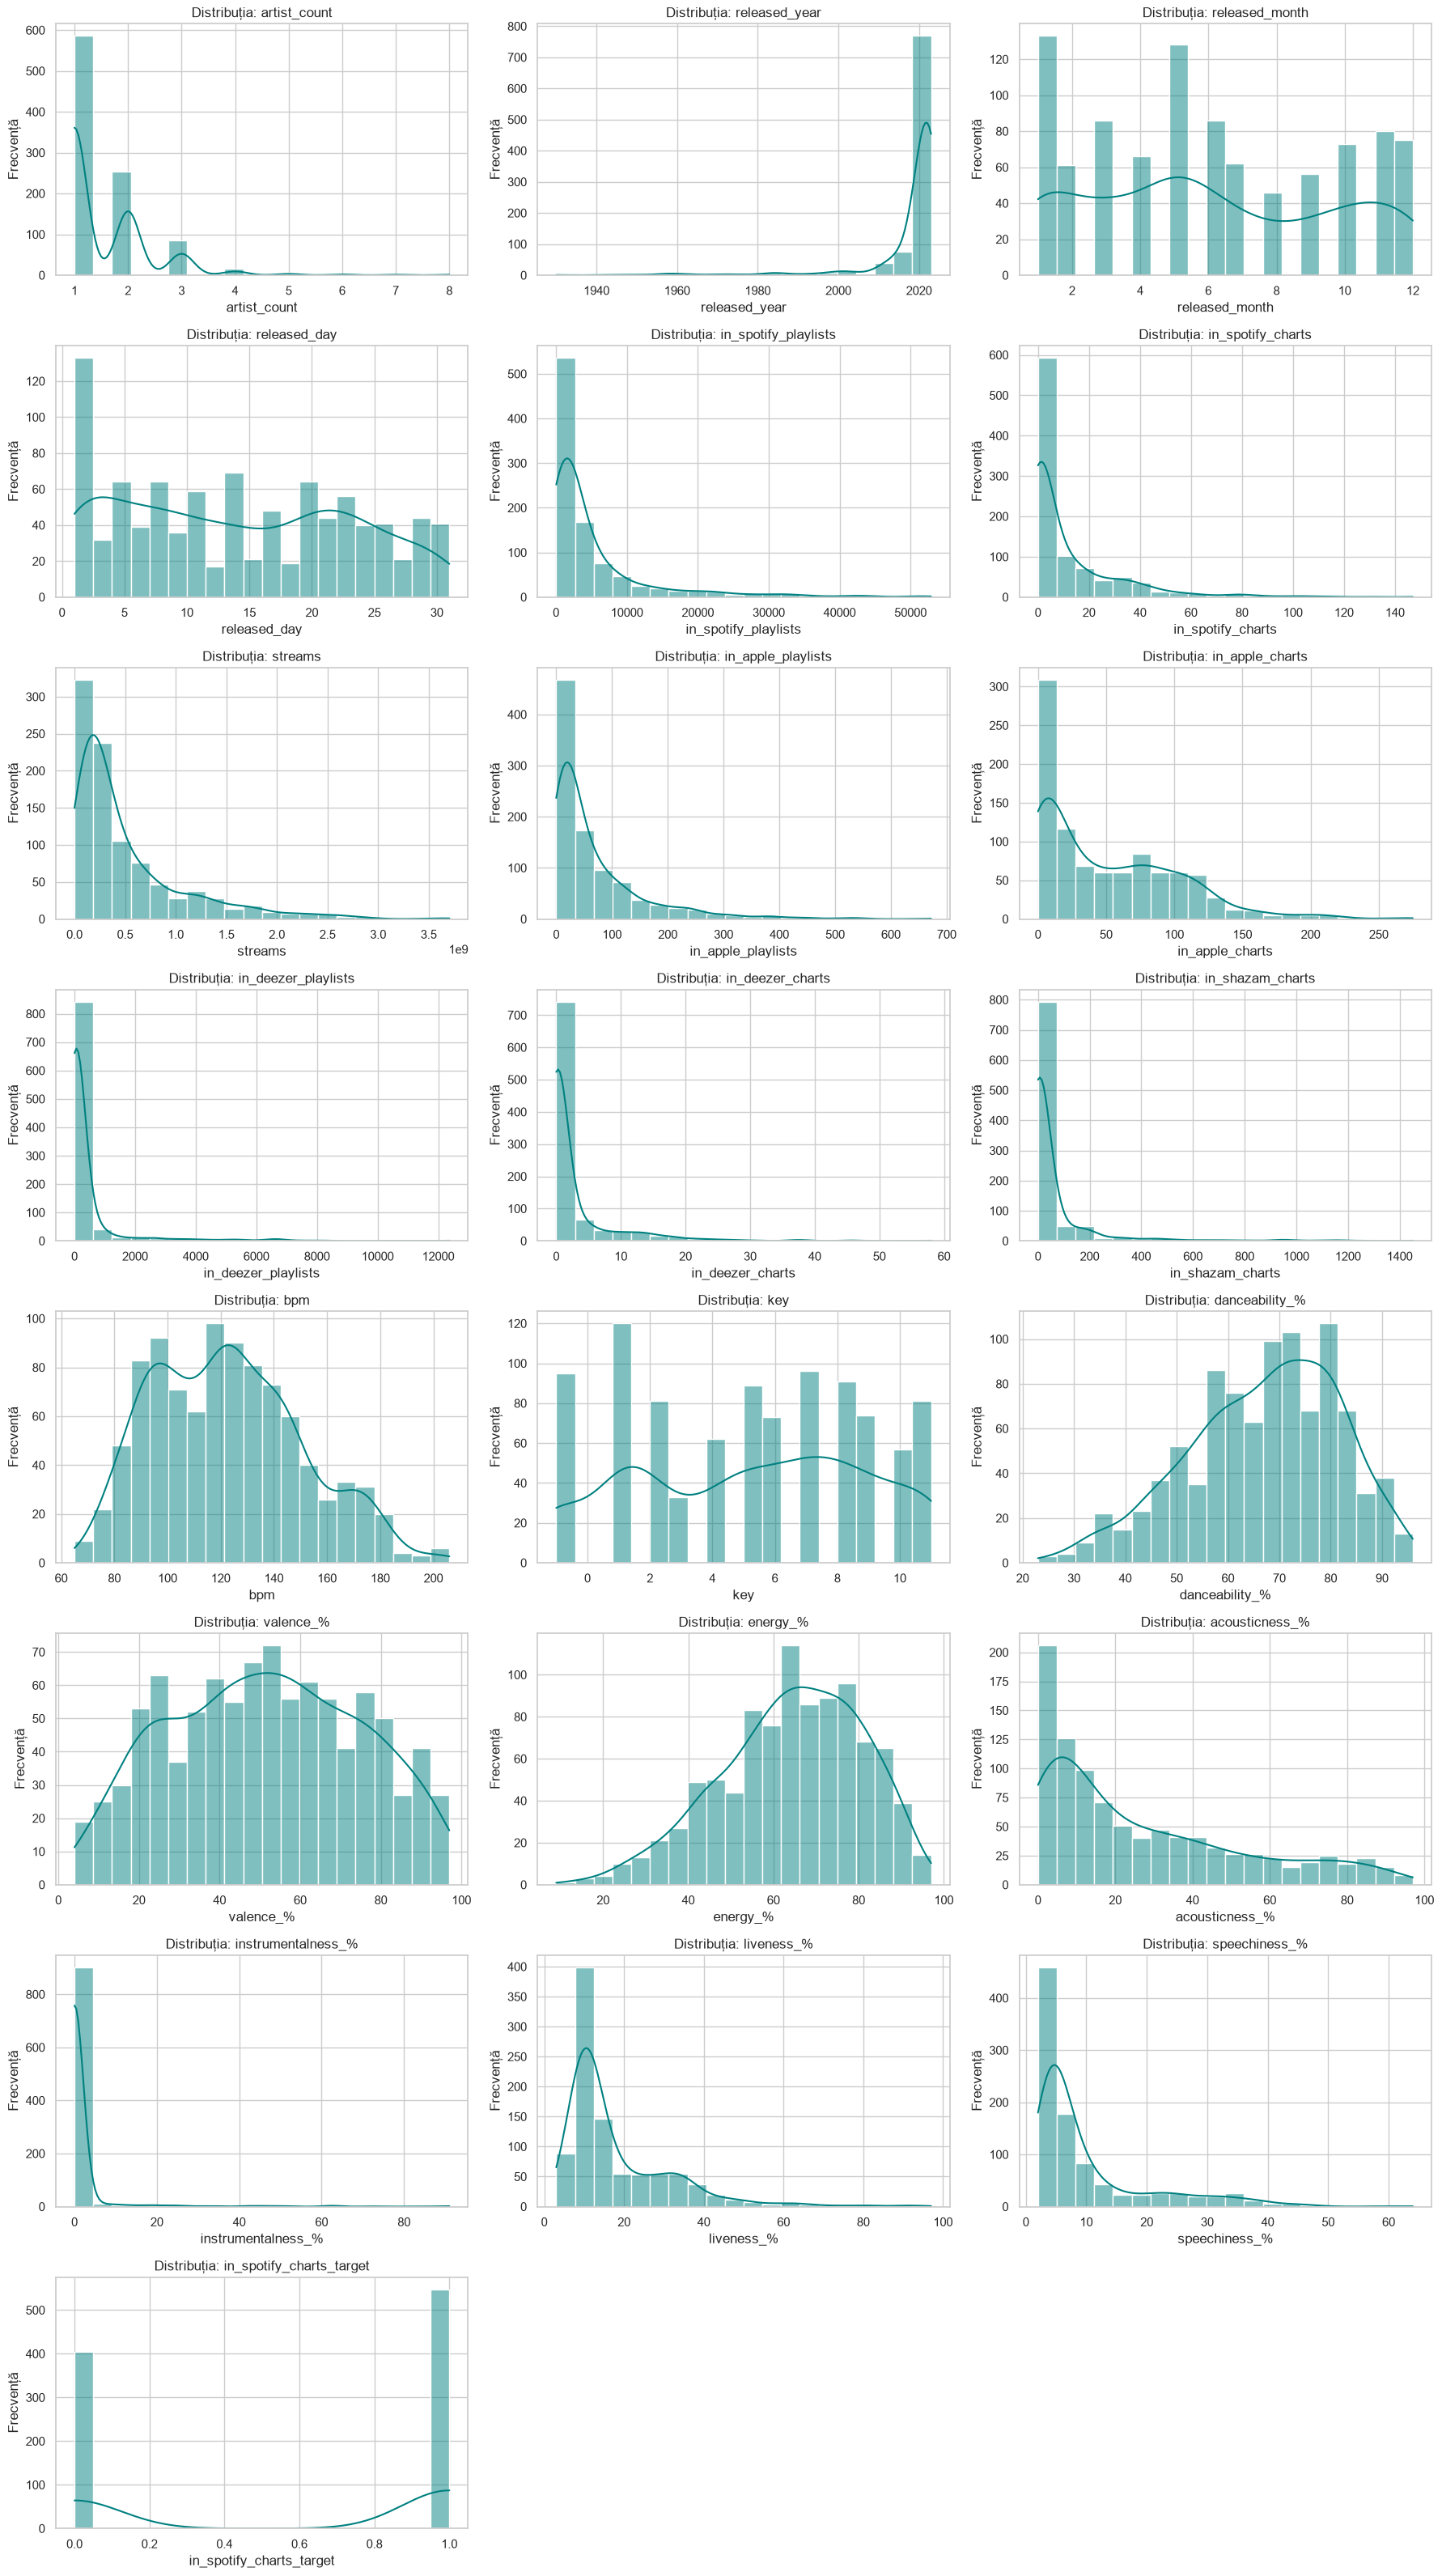

In [6]:
# Selectăm doar coloanele de tip numeric
coloane_numerice = df.select_dtypes(include=['int64', 'float64']).columns

numar_coloane_plot = 3
numar_randuri_plot = (len(coloane_numerice) + numar_coloane_plot - 1) // numar_coloane_plot

plt.figure(figsize=(18, numar_randuri_plot * 4))
for index, col in enumerate(coloane_numerice):
    plt.subplot(numar_randuri_plot, numar_coloane_plot, index + 1)
    sns.histplot(data=df, x=col, bins=20, kde=True, color='teal')
    plt.title(f'Distribuția: {col}')
    plt.xlabel(col)
    plt.ylabel('Frecvență')

plt.tight_layout()
plt.show()

### Analiză: Distribuția variabilelor numerice
* **Distribuții asimetrice (Right-skewed) pentru popularitate:** Variabile precum `streams`, `in_spotify_playlists`, `in_shazam_charts` sau `in_deezer_playlists` au o asimetrie puternică spre dreapta. Asta înseamnă că marea majoritate a pieselor au un număr moderat/mic de ascultări, în timp ce un grup restrâns de piese reprezintă „mega-hituri” cu valori extreme ridicate.
* **Comportament normal pentru caracteristicile audio:** Atributele precum `danceability_%`, `energy_%` și `bpm` urmează o distribuție aproape normală (în formă de clopot), indicând că piesele de succes au tendința de a se încadra în anumite intervale optime de ritm și energie (de exemplu, tempo-ul se concentrează frecvent între 100 și 140 BPM).
* **Valori nule predominante:** Coloana `instrumentalness_%` este aproape în totalitate concentrată spre valoarea 0, ceea ce arată că piesele din topuri sunt predominant vocale, muzica pur instrumentală fiind extrem de rară în topurile Spotify.

## Vizualizarea valorilor extreme (Boxplot-uri)

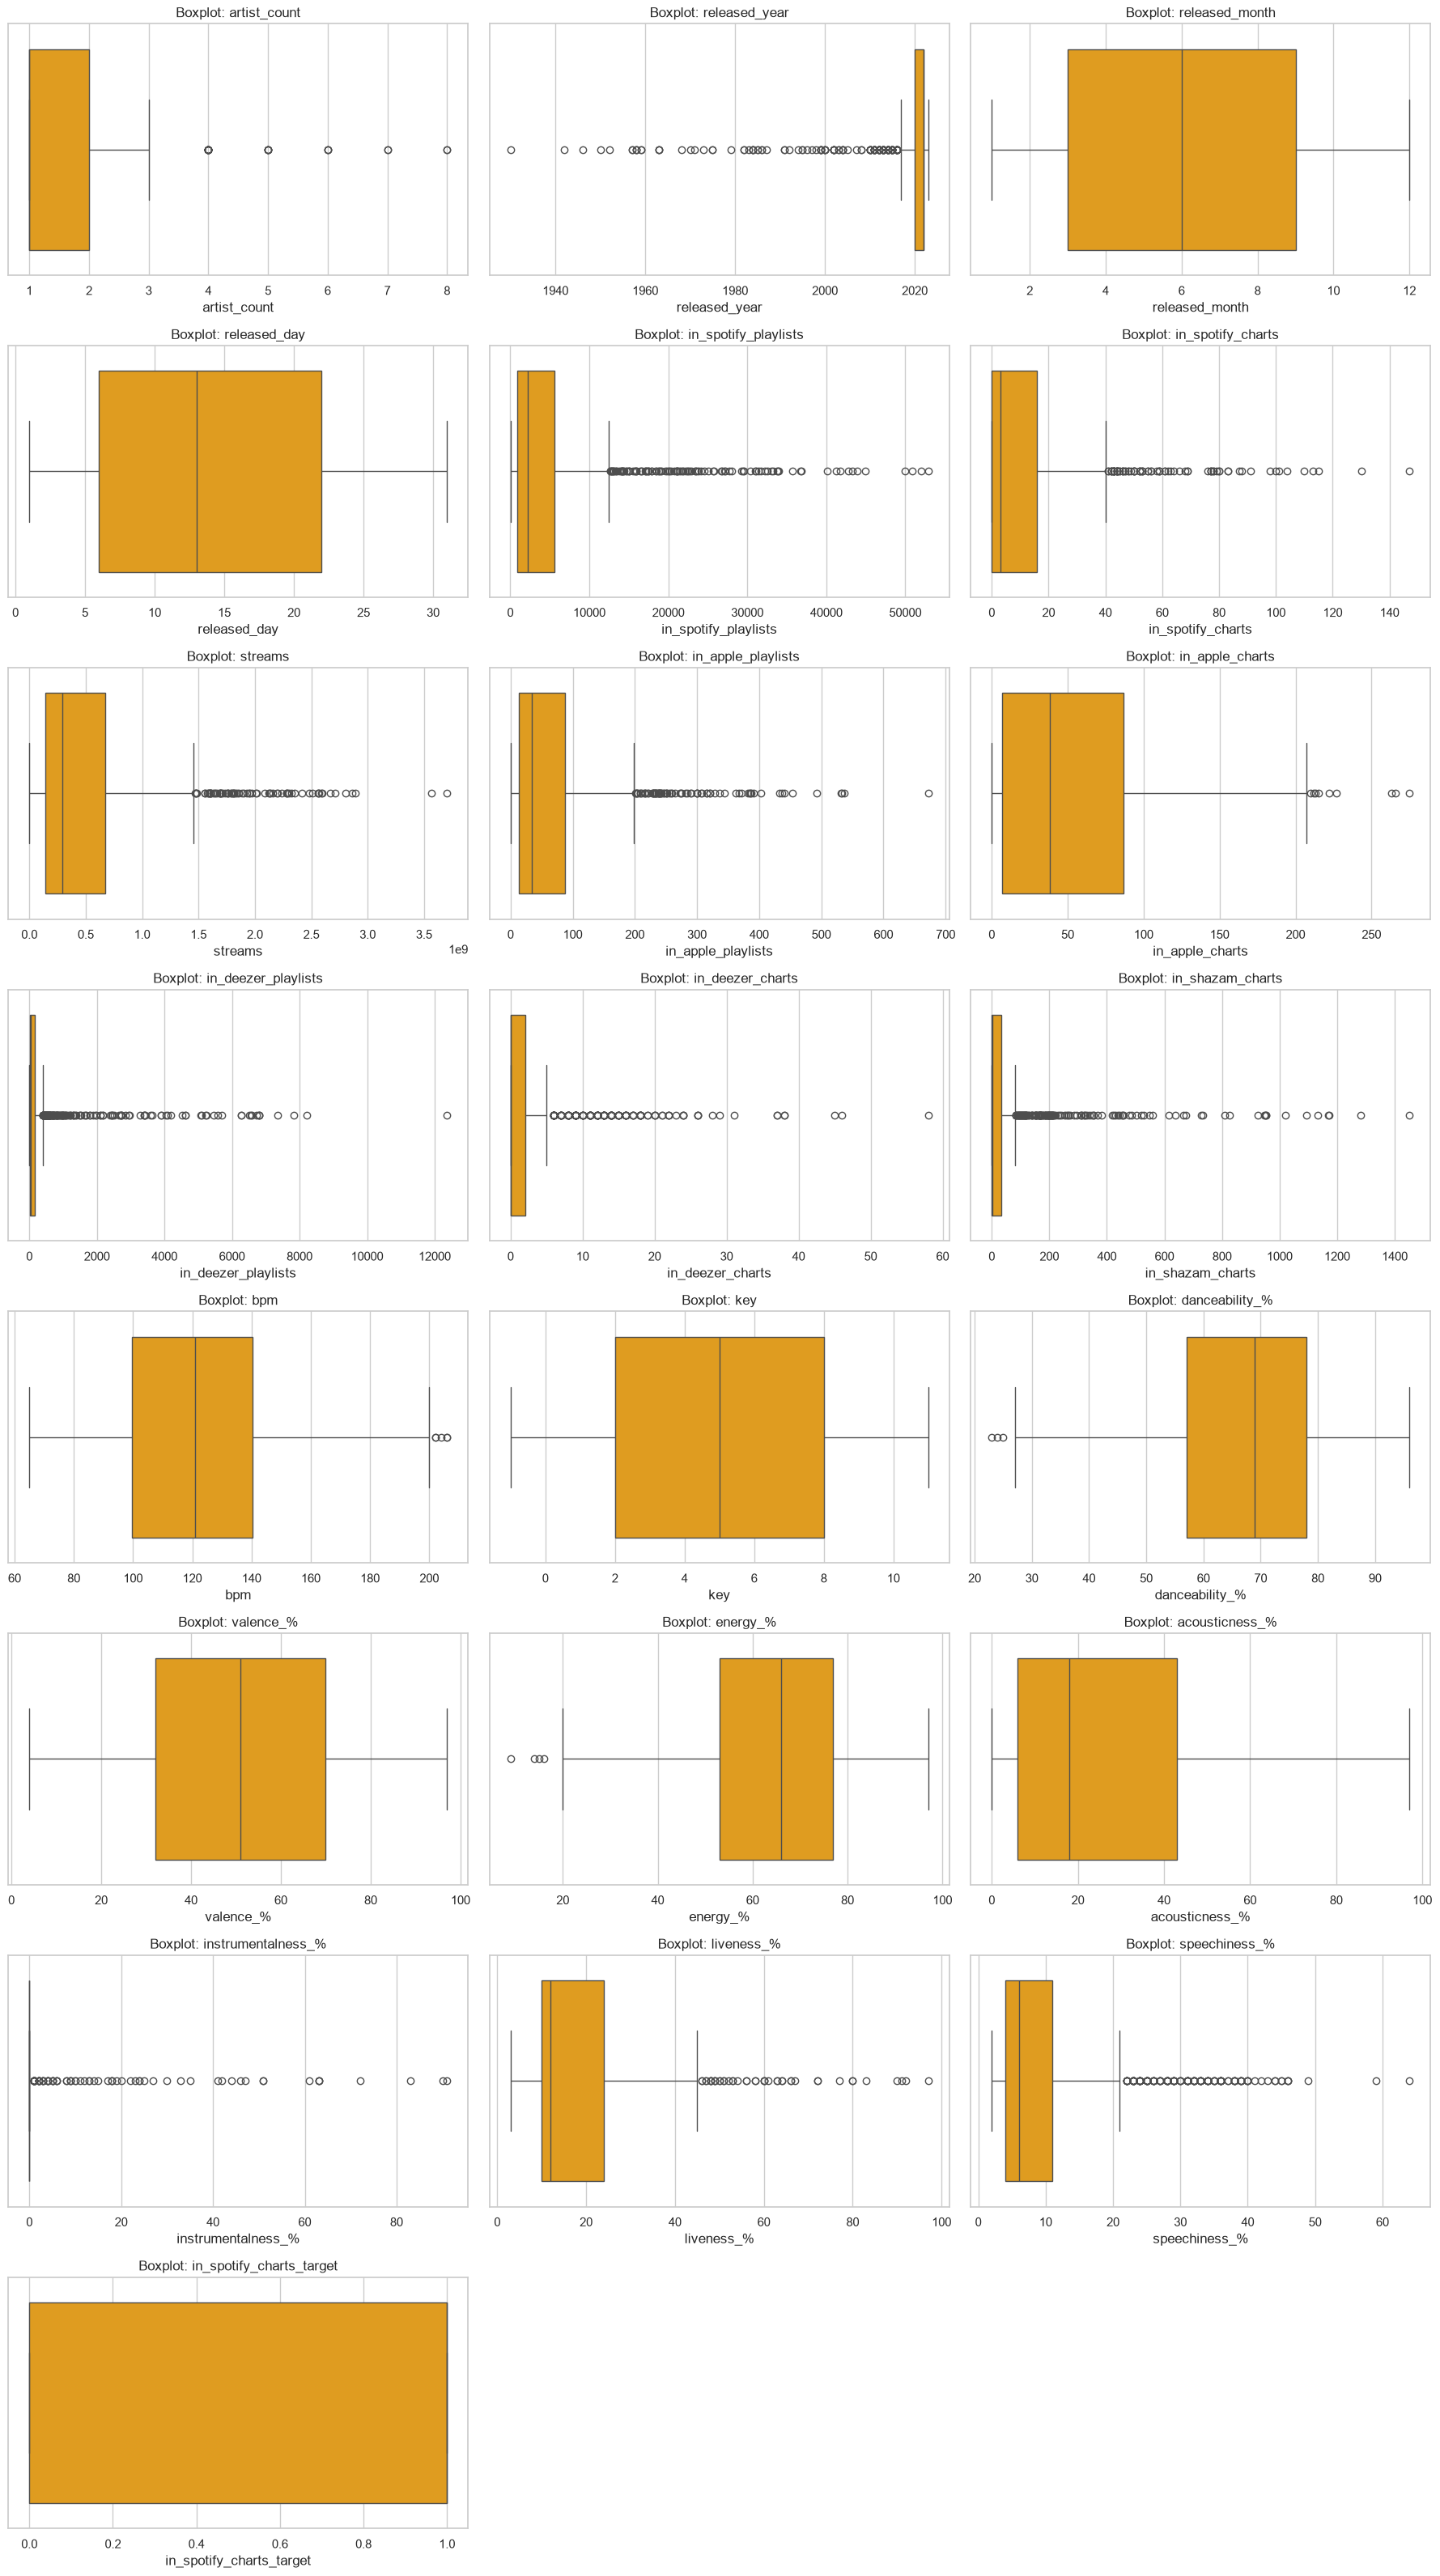

In [7]:
# Vizualizarea valorilor extreme pentru toate coloanele numerice folosind boxplot-uri
coloane_numerice = df.select_dtypes(include=['int64', 'float64']).columns

numar_coloane_plot = 3
numar_randuri_plot = (len(coloane_numerice) + numar_coloane_plot - 1) // numar_coloane_plot

plt.figure(figsize=(18, numar_randuri_plot * 4))
for index, col in enumerate(coloane_numerice):
    plt.subplot(numar_randuri_plot, numar_coloane_plot, index + 1)
    sns.boxplot(data=df, x=col, color='orange')
    plt.title(f'Boxplot: {col}')
    plt.xlabel(col)

plt.tight_layout()
plt.show()

### Analiză: vizualizarea valorilor extreme
* **Prezența mega-hiturilor (Outlieri pozitivi):** Coloanele orientate spre popularitate (cum ar fi `streams`, `in_spotify_playlists`, `in_shazam_charts` sau `in_deezer_playlists`) prezintă numeroși outlieri spre partea superioară. Aceste valori extreme nu sunt erori, ci reflectă fenomenul real al industriei muzicale: piesele care devin „hituri globale” și obțin un volum masiv, disproporționat, de ascultări și intrări în playlisturi față de media generală.
* **Concentrarea caracteristicilor audio:** Atributele legate de structura pieselor (`danceability_%`, `energy_%`, `bpm`) au o distribuție mult mai strânsă în jurul medianei, cu foarte puține valori extreme, ceea ce arată că majoritatea pieselor de succes respectă anumite standarde ritmice.
* **Anomaliile temporale:** La coloana `released_year`, majoritatea datelor sunt concentrate în ultimii ani, punctele izolate din trecut reprezentând piese clasice rare care au supraviețuit decenii în topurile platformei.

## Identificarea outlierilor prin metoda IQR și tratarea lor

In [8]:
# Calculul și afișarea numărului de valori extreme pentru fiecare coloană numerică
rezultate_outliers = []

for col in coloane_numerice:
    arr = df[col].values
    q1 = np.quantile(arr, 0.25)
    q3 = np.quantile(arr, 0.75)
    iqr = q3 - q1

    limita_superioara = q3 + (1.5 * iqr)
    limita_inferioara = q1 - (1.5 * iqr)

    outliers = arr[(arr <= limita_inferioara) | (arr >= limita_superioara)]
    rezultate_outliers.append({
        'Coloană': col, 
        'Număr Outliers': len(outliers),
        'Procent (%)': round((len(outliers) / len(arr)) * 100, 2)
    })

# Convertim în DataFrame și sortăm descrescător după numărul de outlieri
df_outliers = pd.DataFrame(rezultate_outliers).sort_values(by='Număr Outliers', ascending=False)

# Afișare tabelară curată
display(df_outliers.reset_index(drop=True))

,Coloană,Număr Outliers,Procent (%)
0,instrumentalness_%,952,100.00
1,released_year,173,18.17
2,in_deezer_charts,161,16.91
3,in_deezer_playlists,154,16.18
4,in_shazam_charts,145,15.23
5,speechiness_%,136,14.29
6,in_spotify_playlists,109,11.45
7,in_spotify_charts,82,8.61
8,in_apple_playlists,78,8.19
9,streams,74,7.77


### Decizie privind Outlierii 
* **Natura outlierilor în industria muzicală:** Majoritatea valorilor extreme identificate pe coloanele de popularitate (`streams`, `playlist-uri`, `chart-uri`) reprezintă de fapt hiturile globale ale pieței, nu erori de înregistrare. Prin urmare, acestea nu trebuie eliminate, deoarece conțin tocmai semnalul pe care dorim să îl analizăm.
* **Limitarea metodei IQR pe distribuții asimetrice:** În cazul unor atribute precum `instrumentalness_%`, unde majoritatea covârșitoare a valorilor sunt zero, formula IQR clasifică greșit datele normale drept outlieri. Acest lucru subliniază importanța analizei vizuale (boxplot) înainte de a lua decizii distructive asupra setului de date (cum ar fi eliminarea masivă a înregistrărilor).
* **Strategia adoptată:** Păstrăm integritatea setului de date complet pentru etapele de modelare predictive.

## Matricea de corelație Pearson pentru variabilele numerice

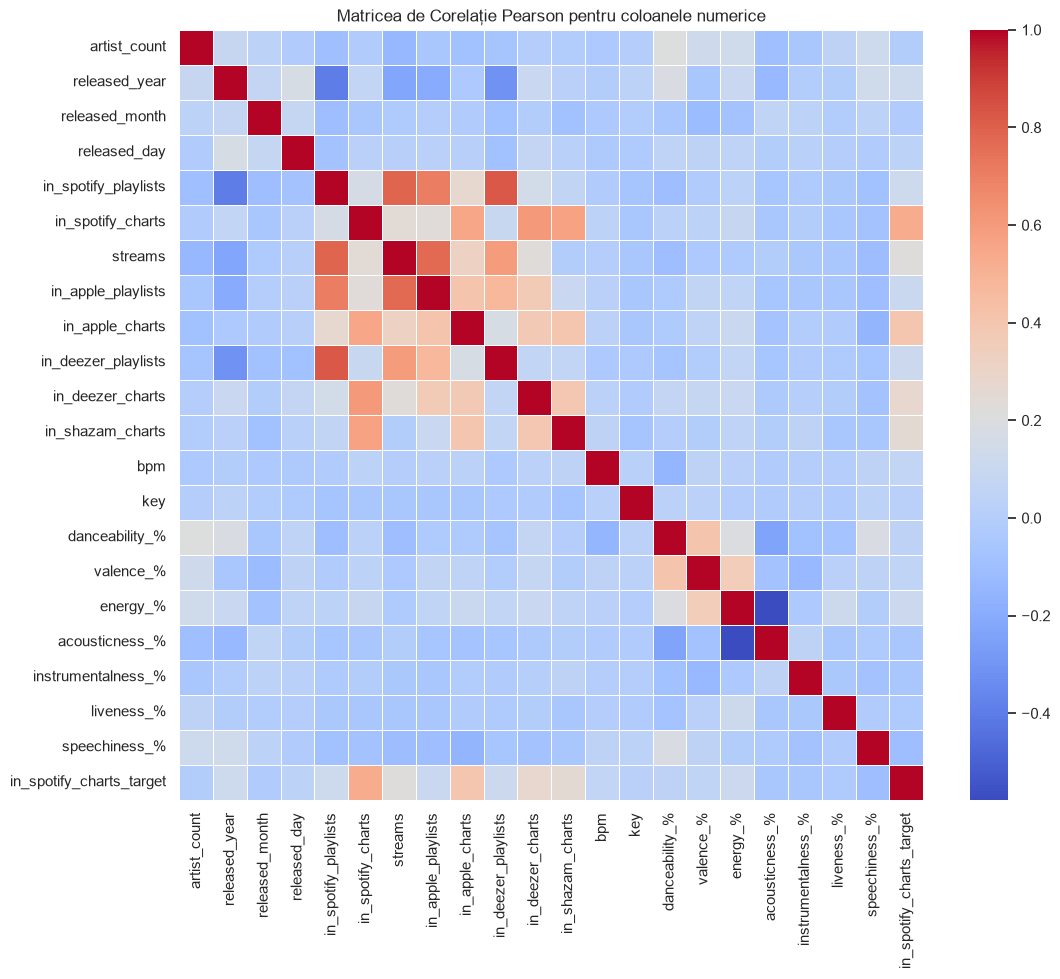

In [9]:
# Standardizarea coloanelor numerice pentru o corelație corectă
from sklearn.preprocessing import StandardScaler

coloane_numerice = df.select_dtypes(include=['int64', 'float64']).columns
scaler = StandardScaler()
df_standardizat_numeric = pd.DataFrame(scaler.fit_transform(df[coloane_numerice]), columns=coloane_numerice)

# Generarea matricei de corelație Pearson
plt.figure(figsize=(12, 10))
sns.heatmap(df_standardizat_numeric.corr(), annot=False, cmap='coolwarm', linewidths=0.5)
plt.title("Matricea de Corelație Pearson pentru coloanele numerice")
plt.show()

### Analiză: Matricea de Corelație Pearson
* **Corelație puternică între platformele de streaming:** Există o corelație pozitivă foarte intensă (culoare roșu aprins) între numărul de playlisturi pe diverse platforme (`in_spotify_playlists`, `in_apple_playlists`, `in_deezer_playlists`) și numărul total de ascultări (`streams`). Asta demonstrează că prezența în playlisturile editoriale este principalul motor al popularității unei piese.
* **Corelație inversă pe caracteristici audio:** Se observă corelații negative clare între `energy_%` și `acousticness_%` (un comportament muzical standard: piesele foarte energice au tendința de a fi mai puțin acustice).
* **Relația cu variabila țintă (`in_spotify_charts_target`):** Variabila țintă prezintă corelații pozitive moderate spre ridicate cu prezența în topurile și playlisturile principalelor platforme, confirmând că expunerea extinsă crește masiv șansele ca o piesă să intre în topuri.

## Matricea de corelație Spearman pentru variabilele categorice

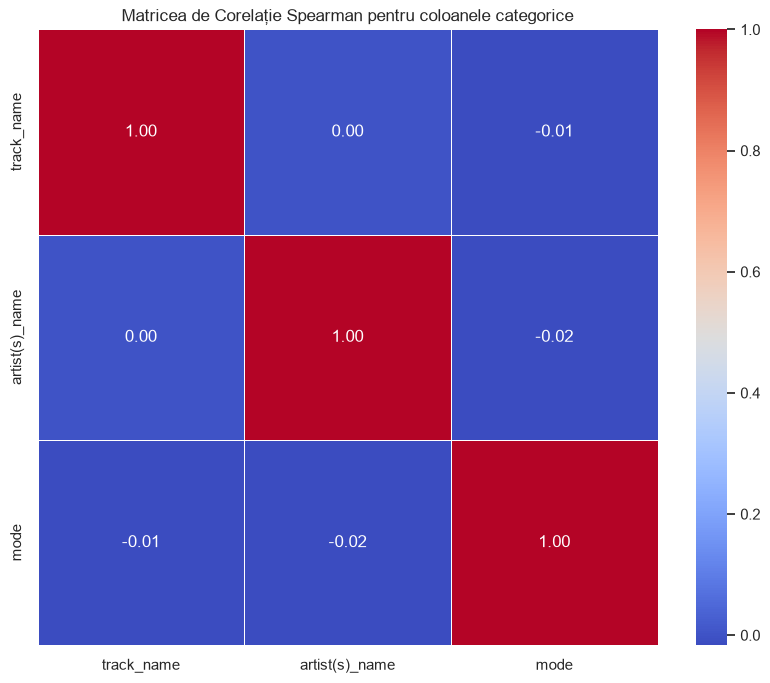

In [10]:
from sklearn.preprocessing import LabelEncoder

df_copy = df.copy()
label_encoder = LabelEncoder()
coloane_categoriale = df_copy.select_dtypes(include=['object']).columns

# Codificarea variabilelor categorice
for col in coloane_categoriale:
    df_copy[col] = label_encoder.fit_transform(df_copy[col].astype(str))

scaler = StandardScaler()
df_standardized_cat = pd.DataFrame(scaler.fit_transform(df_copy[coloane_categoriale]), columns=coloane_categoriale)

# Generarea matricei Spearman
plt.figure(figsize=(10, 8))
sns.heatmap(df_standardized_cat.corr(method='spearman'), annot=True, cmap='coolwarm', fmt=".2f", linewidths=.5)
plt.title("Matricea de Corelație Spearman pentru coloanele categorice")
plt.show()

### Analiză: Matricea de Corelație Spearman
- **Independența identificatorilor unici:** Corelațiile de 0.00 dintre `track_name` și `artist(s)_name` confirmă că acestea sunt atribute de tip text unic (nume de piese și artiști), care nu pot fi corelate matematic în această formă.
- **Natura coloanei `mode`:** Variabila `mode` (care indică tonalitatea Major/Minor) nu prezintă nicio corelație cu numele pieselor sau artiștilor, fiind o caracteristică muzicală independentă.
- **Implicație pentru modelare:** Această matrice întărește concluzia că variabilele textuale brute (nume, artiști) necesită tehnici speciale de inginerie a datelor (cum ar fi One-Hot Encoding) dacă dorim să le integrăm în modele predictive.

## Analiza Componentelor Principale (PCA)

In [11]:
from sklearn.decomposition import PCA

# Aplicarea PCA pentru a reține 90% din varianța datelor
pca = PCA(n_components=0.90)
components = pca.fit_transform(df_standardizat_numeric)

print(f"Numărul de componente principale necesare pentru a acoperi 90% din varianță: {components.shape[1]}")

Numărul de componente principale necesare pentru a acoperi 90% din varianță: 16


### Analiză: Reducerea Dimensionalității prin PCA
* **Grad scăzut de redundanță:** Necesitatea a 16 componente din totalul de coloane numerice indică faptul că majoritatea caracteristicilor din setul de date sunt relativ independente și aduc informație unică.
* **Impactul asupra modelelor:** Deoarece PCA a redus dimensionalitatea cu doar câteva coloane (de la ~22 la 16), înseamnă că setul de date este deja compact. Pentru modelele de Machine Learning, s-ar putea să fie chiar mai avantajos să antrenăm direct pe caracteristicile originale (sau pe o selecție a lor), evitând pierderea de interpretabilitate pe care o aduce transformarea PCA.

## Tendințe, trenduri și relații între variabile

## Corelația fiecărei coloane numerice cu variabila țintă

In [12]:
# Calculăm corelația Pearson a tuturor coloanelor numerice față de variabila țintă
matrice_corelatie = df_standardizat_numeric.copy()
matrice_corelatie['in_spotify_charts_target'] = df['in_spotify_charts_target']

corelatii_tinta = matrice_corelatie.corr()['in_spotify_charts_target'].sort_values(ascending=False)

print("Corelația variabilelor numerice cu 'in_spotify_charts_target':")
display(corelatii_tinta.to_frame(name='Corelație'))

Corelația variabilelor numerice cu 'in_spotify_charts_target':


,Corelație
in_spotify_charts_target,1.000000
in_spotify_charts,0.527402
in_apple_charts,0.397620
in_deezer_charts,0.276209
in_shazam_charts,0.251106
streams,0.220106
released_year,0.123726
in_spotify_playlists,0.122279
in_deezer_playlists,0.111649
energy_%,0.108611


### Analiză: Corelația caracteristicilor cu Variabila Țintă (`in_spotify_charts_target`)
* **Factorii principali ai succesului:** Prezența în topurile altor platforme de streaming (`in_apple_charts`, `in_deezer_charts`, `in_shazam_charts`) și volumul total de ascultări (`streams`) corelează cel mai puternic cu variabila țintă, indicând că popularitatea cross-platform este cel mai bun indicator al succesului pe Spotify.
* **Rolul caracteristicilor audio:** Atributele tehnice ale pieselor (cum ar fi `bpm`, `danceability_%` sau `energy_%`) au o corelație liniară slabă cu prezența în topuri, sugerând că succesul comercial depinde mai mult de factori de marketing/distribuție decât exclusiv de structura audio a melodiilor.

## Histograme stivuite în funcție de clasa țintă

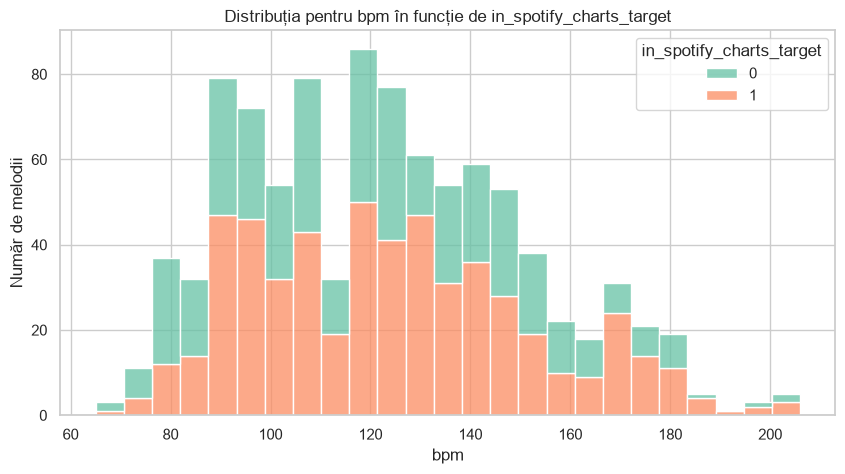

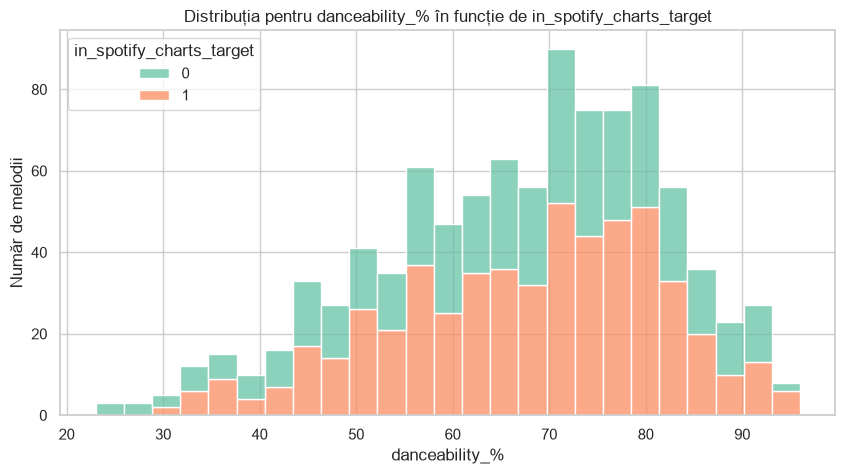

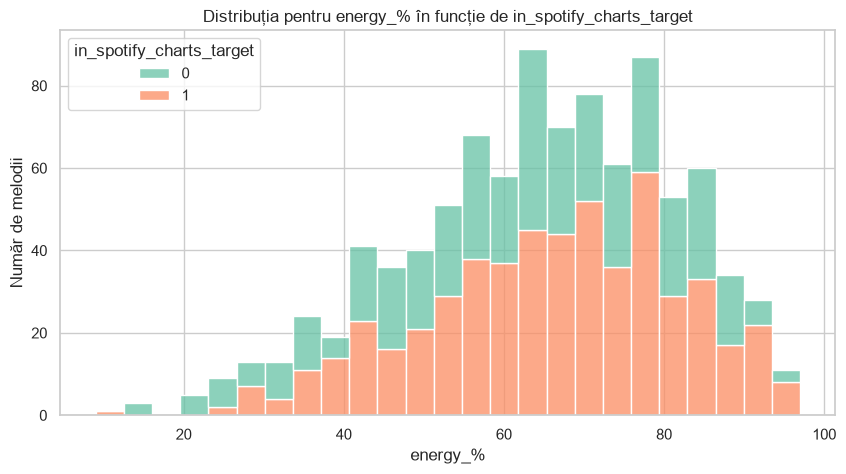

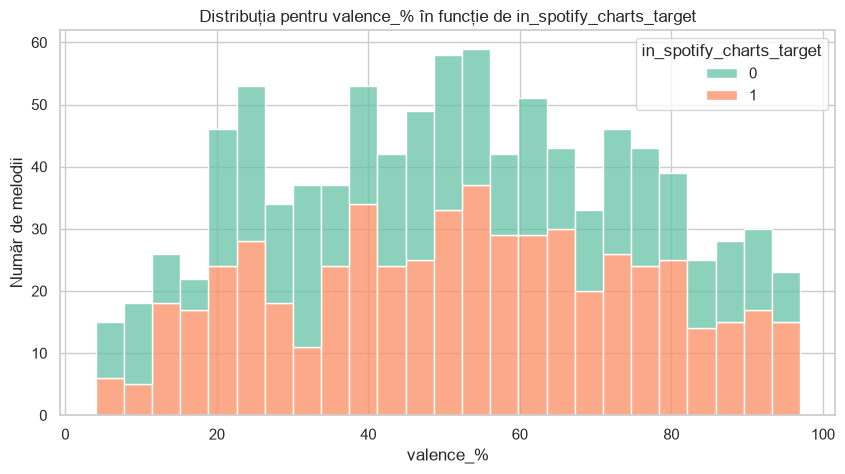

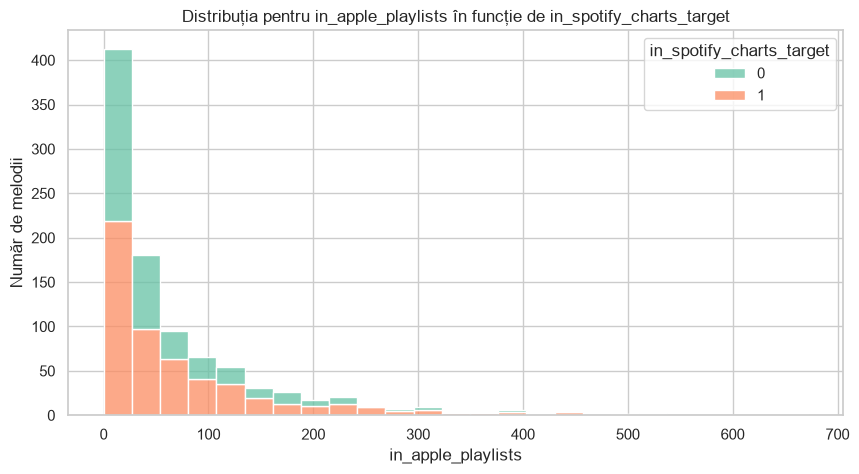

In [13]:
coloana_tinta = "in_spotify_charts_target"

# Selectăm câteva coloane relevante pentru a nu genera zeci de grafice greu de parcurs
coloane_de_analizat = ['bpm', 'danceability_%', 'energy_%', 'valence_%', 'in_apple_playlists']

for column in coloane_de_analizat:
    if column in df.columns:
        plt.figure(figsize=(10, 5))
        sns.histplot(data=df, x=column, hue=coloana_tinta, multiple="stack", bins=25, palette='Set2')
        plt.title(f'Distribuția pentru {column} în funcție de {coloana_tinta}')
        plt.xlabel(column)
        plt.ylabel('Număr de melodii')
        plt.show()

### Analiză: Histograme stivuite în funcție de clasa țintă
- **Suprapunerea caracteristicilor audio:** Distribuțiile pentru piese care intră în topuri (1) și cele care nu intră (0) se suprapun considerabil pe atribute precum `bpm`, `danceability_%`, `energy_%` și `valence_%`. Asta explică de ce corelațiile de dinainte au fost slabe: o piesă poate avea un tempo sau o dansabilitate bună, dar asta nu garantează automat intrarea în topuri.
- **Standarde universale:** Indiferent de succes, majoritatea pieselor se concentrează în aceleași intervale standard (de exemplu, BPM între 100 și 130 sau energie și dansabilitate peste 60%), fiind practic „rețeta” de bază a muzicii comerciale.
- **Impactul playlisturilor externe (`in_apple_playlists`):** Spre deosebire de atributele audio, în cazul prezenței în playlisturile de pe alte platforme se observă clar că melodiile cu valori mai mari au o pondere mult mai mare de culoare portocalie (1), confirmând că expunerea externă crește șansele de succes pe Spotify.

# II. Modelare clasificatori

## Pregătirea datelor, împărțirea setului (Train/Test) și definirea funcției de evaluare

In [14]:
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler, LabelEncoder
import sklearn.metrics as met

# 1. Curățarea coloanelor text și a coloanei care cauzează Data Leakage
df_ml = df.copy()

# Adăugăm 'in_spotify_charts' pe lista coloanelor de exclus din X
coloane_de_exclus = ['track_name', 'artist(s)_name', 'in_spotify_charts']

for col in coloane_de_exclus:
    if col in df_ml.columns:
        df_ml = df_ml.drop(col, axis=1)

# 2. Codificarea variabilei 'mode' (Major/Minor în valori numerice)
label_encoder = LabelEncoder()
if 'mode' in df_ml.columns:
    df_ml['mode'] = label_encoder.fit_transform(df_ml['mode'])

# 3. Separarea în set de caracteristici (X) și variabilă țintă (y)
X = df_ml.drop(['in_spotify_charts_target'], axis=1)
y = df_ml['in_spotify_charts_target']

# 4. Împărțirea datelor în set de antrenare și testare (cu stratificare pentru păstrarea proporției claselor)
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.3, stratify=y, random_state=9)

# 5. Standardizarea datelor numerice
scaler = StandardScaler()
X_train = scaler.fit_transform(X_train)
X_test = scaler.transform(X_test)

print(f"Dimensiunea setului de antrenare: {X_train.shape}")
print(f"Dimensiunea setului de testare: {X_test.shape}")

# 6. Funcția unificată pentru afișarea matricii de confuzie și a metricilor de performanță
def acuratetea_clasificatorului(model_clasificare, y_predicted):
    print(f'Matrice confuzie pe X_test cu {model_clasificare}:\n')
    disp = met.ConfusionMatrixDisplay(met.confusion_matrix(y_test, y_predicted))
    disp.plot(cmap='Blues')
    plt.show()
    
    metrics = met.precision_recall_fscore_support(y_test, y_predicted, average=None)
    print(f'Acuratețe generală: {round(met.accuracy_score(y_test, y_predicted), 2)}\n')
    
    df_results = pd.DataFrame([
        {'metric': 'Precision', 'class 0': round(metrics[0][0], 2), 'class 1': round(metrics[0][1], 2)},
        {'metric': 'Recall', 'class 0': round(metrics[1][0], 2), 'class 1': round(metrics[1][1], 2)},
        {'metric': 'F1-score', 'class 0': round(metrics[2][0], 2), 'class 1': round(metrics[2][1], 2)}
    ])
    
    display(df_results)

Dimensiunea setului de antrenare: (666, 21)
Dimensiunea setului de testare: (286, 21)


## Antrenarea și evaluarea modelelor de Machine Learning (Logistic Regression, KNN, Decision Tree și Random Forest)

Matrice confuzie pe X_test cu Regresia logistica:



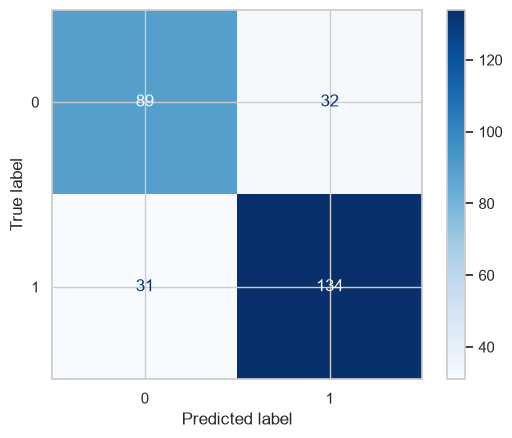

Acuratețe generală: 0.78



,metric,class 0,class 1
0,Precision,0.74,0.81
1,Recall,0.74,0.81
2,F1-score,0.74,0.81


Matrice confuzie pe X_test cu KNN:



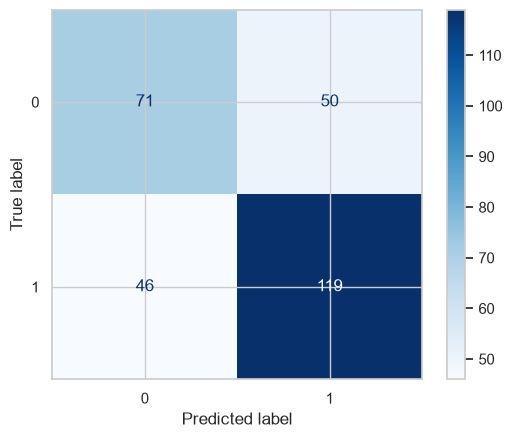

Acuratețe generală: 0.66



,metric,class 0,class 1
0,Precision,0.61,0.70
1,Recall,0.59,0.72
2,F1-score,0.60,0.71


Matrice confuzie pe X_test cu Arbore de decizie:



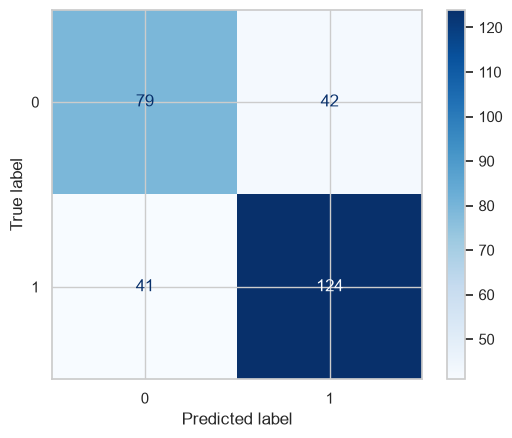

Acuratețe generală: 0.71



,metric,class 0,class 1
0,Precision,0.66,0.75
1,Recall,0.65,0.75
2,F1-score,0.66,0.75


Matrice confuzie pe X_test cu Padure aleatoare:



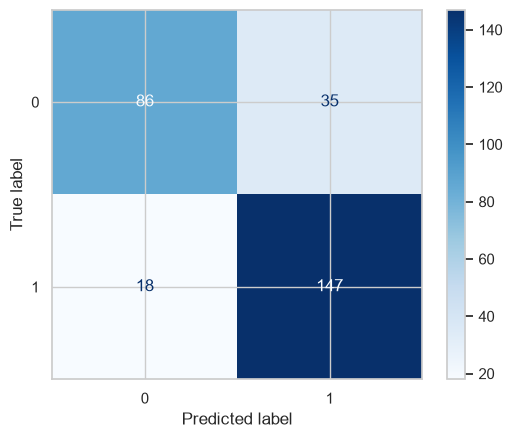

Acuratețe generală: 0.81



,metric,class 0,class 1
0,Precision,0.83,0.81
1,Recall,0.71,0.89
2,F1-score,0.76,0.85


In [15]:
from sklearn.linear_model import LogisticRegression
from sklearn.neighbors import KNeighborsClassifier
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier

# --- 1. Regresia Logistică ---
regresia_logistica_clasificator = LogisticRegression(random_state=9)
regresia_logistica_clasificator.fit(X_train, y_train)

y_pred_regresia_logistica = regresia_logistica_clasificator.predict(X_test)
acuratetea_clasificatorului('Regresia logistica', y_pred_regresia_logistica)

# --- 2. K-Nearest Neighbors (KNN) ---
knn_clasificator = KNeighborsClassifier(n_neighbors=10)
knn_clasificator.fit(X_train, y_train)

y_pred_knn = knn_clasificator.predict(X_test)
acuratetea_clasificatorului('KNN', y_pred_knn)

# --- 3. Arborele de Decizie ---
arborde_decizie_clasificare = DecisionTreeClassifier(random_state=9)
arborde_decizie_clasificare.fit(X_train, y_train)

y_pred_arbore_decizie = arborde_decizie_clasificare.predict(X_test)
acuratetea_clasificatorului('Arbore de decizie', y_pred_arbore_decizie)

# --- 4. Pădurea Aleatoare (Random Forest) ---
padure_aleatoare_clasificare = RandomForestClassifier(n_estimators=200, max_samples=0.3, random_state=9)
padure_aleatoare_clasificare.fit(X_train, y_train)

y_pred_padure_aleatoare = padure_aleatoare_clasificare.predict(X_test)
acuratetea_clasificatorului('Padure aleatoare', y_pred_padure_aleatoare)

## Optimizarea hiperparametrilor folosind GridSearchCV

Cei mai buni parametri pentru regresia logistica:  {'C': 1, 'penalty': 'l2', 'solver': 'lbfgs'}
Cel mai bun estimator pentru regresia logistica:  LogisticRegression(C=1, penalty='l2', random_state=9)
Matrice confuzie pe X_test cu Optimizare Regresia logistica:



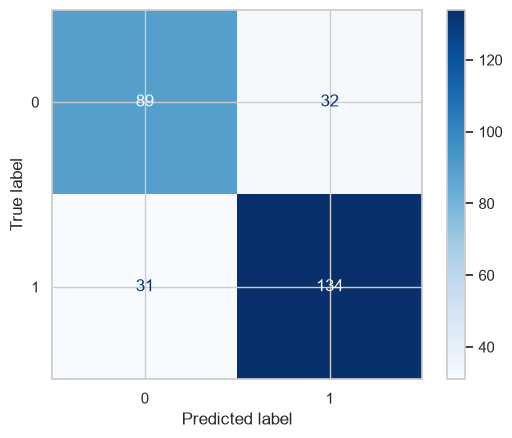

Acuratețe generală: 0.78



,metric,class 0,class 1
0,Precision,0.74,0.81
1,Recall,0.74,0.81
2,F1-score,0.74,0.81


Cei mai buni parametri pentru KNN:  {'metric': 'manhattan', 'n_neighbors': 14, 'weights': 'uniform'}
Cel mai bun estimator pentru KNN:  KNeighborsClassifier(metric='manhattan', n_neighbors=14)
Matrice confuzie pe X_test cu Optimizare KNN:



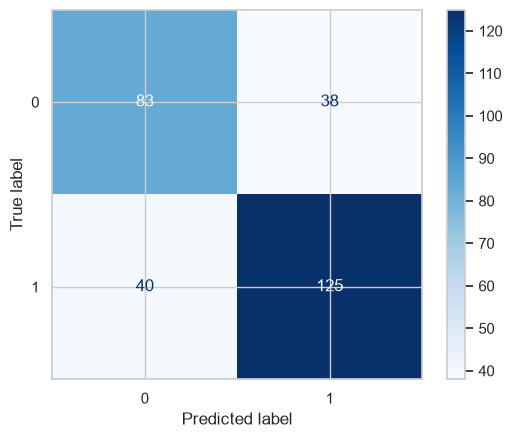

Acuratețe generală: 0.73



,metric,class 0,class 1
0,Precision,0.67,0.77
1,Recall,0.69,0.76
2,F1-score,0.68,0.76


Cei mai buni parametri pentru Arbore decizie:  {'criterion': 'entropy', 'max_depth': 10, 'min_samples_leaf': 4, 'min_samples_split': 10}
Cel mai bun estimator pentru Arbore decizie:  DecisionTreeClassifier(criterion='entropy', max_depth=10, min_samples_leaf=4,
                       min_samples_split=10, random_state=9)
Matrice confuzie pe X_test cu Optimizare Arbore decizie:



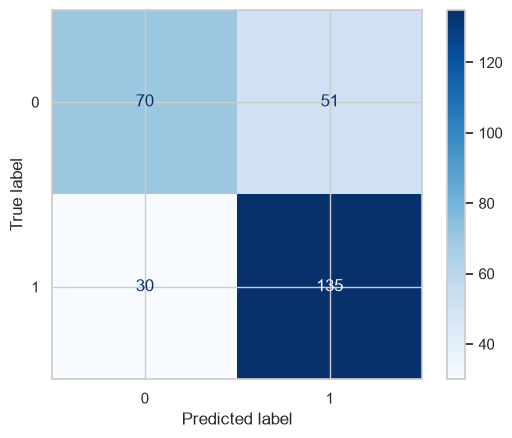

Acuratețe generală: 0.72



,metric,class 0,class 1
0,Precision,0.70,0.73
1,Recall,0.58,0.82
2,F1-score,0.63,0.77


Fitting 5 folds for each of 8 candidates, totalling 40 fits
Cei mai buni parametri pentru Padure aleatoare:  {'max_depth': None, 'min_samples_split': 3, 'n_estimators': 20}
Cel mai bun estimator pentru Padure aleatoare:  RandomForestClassifier(min_samples_split=3, n_estimators=20, random_state=9)
Matrice confuzie pe X_test cu Optimizare Padure aleatoare:



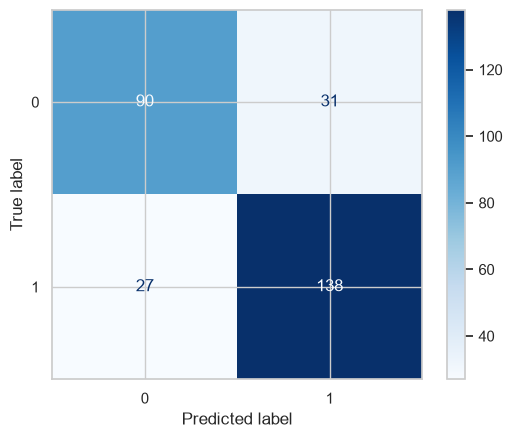

Acuratețe generală: 0.8



,metric,class 0,class 1
0,Precision,0.77,0.82
1,Recall,0.74,0.84
2,F1-score,0.76,0.83


In [16]:
from sklearn.model_selection import GridSearchCV

# --- 1. Optimizare Regresia Logistică ---
parametri_grid_regresie_logistica = {
    'C': [0.0001, 0.001, 0.01, 0.1, 1, 10, 100], 
    'penalty': ['l2'], 
    'solver': ['lbfgs', 'liblinear']
}

grid_search_regresie_logistica = GridSearchCV(LogisticRegression(random_state=9), parametri_grid_regresie_logistica, cv=5, scoring='accuracy')
grid_search_regresie_logistica.fit(X_train, y_train)

best_params_regresie_logistica = grid_search_regresie_logistica.best_params_
best_estimator_regresie_logistica = grid_search_regresie_logistica.best_estimator_

print("Cei mai buni parametri pentru regresia logistica: ", best_params_regresie_logistica)
print("Cel mai bun estimator pentru regresia logistica: ", best_estimator_regresie_logistica)

y_pred_regresie_logistica_optimizata = best_estimator_regresie_logistica.predict(X_test)
acuratetea_clasificatorului('Optimizare Regresia logistica', y_pred_regresie_logistica_optimizata)

# --- 2. Optimizare KNN ---
parametri_grid_knn = {
    'n_neighbors': [3, 5, 7, 9, 11, 13, 14, 15, 16],
    'weights': ['uniform', 'distance'],
    'metric': ['euclidean', 'manhattan']
}

grid_search_knn = GridSearchCV(KNeighborsClassifier(), parametri_grid_knn, cv=5, scoring='accuracy')
grid_search_knn.fit(X_train, y_train)

best_params_knn = grid_search_knn.best_params_
best_estimator_knn = grid_search_knn.best_estimator_

print("Cei mai buni parametri pentru KNN: ", best_params_knn)
print("Cel mai bun estimator pentru KNN: ", best_estimator_knn)

y_pred_knn_optimizata = best_estimator_knn.predict(X_test)
acuratetea_clasificatorului('Optimizare KNN', y_pred_knn_optimizata)

# --- 3. Optimizare Arbore de Decizie ---
param_grid_arbore_decizie = {
    'criterion': ['gini', 'entropy'],
    'max_depth': [None, 10, 20, 30, 40, 50],
    'min_samples_split': [2, 5, 10],
    'min_samples_leaf': [1, 2, 4]
}

grid_search_arbore_decizie = GridSearchCV(DecisionTreeClassifier(random_state=9), param_grid_arbore_decizie, cv=5, scoring='accuracy')
grid_search_arbore_decizie.fit(X_train, y_train)

best_params_arbore_decizie = grid_search_arbore_decizie.best_params_
best_estimator_arbore_decizie = grid_search_arbore_decizie.best_estimator_

print("Cei mai buni parametri pentru Arbore decizie: ", best_params_arbore_decizie)
print("Cel mai bun estimator pentru Arbore decizie: ", best_estimator_arbore_decizie)

y_pred_arbore_decizie_optimizata = best_estimator_arbore_decizie.predict(X_test)
acuratetea_clasificatorului('Optimizare Arbore decizie', y_pred_arbore_decizie_optimizata)

# --- 4. Optimizare Pădure Aleatoare ---
param_grid_padure_aleatoare = {
    'n_estimators': [10, 20], 
    'max_depth': [None, 5], 
    'min_samples_split': [2, 3]
}

grid_search_padure_aleatoare = GridSearchCV(RandomForestClassifier(random_state=9), param_grid_padure_aleatoare, cv=5, n_jobs=-1, verbose=1)
grid_search_padure_aleatoare.fit(X_train, y_train)

best_params_padure_aleatoare = grid_search_padure_aleatoare.best_params_
best_estimator_padure_aleatoare = grid_search_padure_aleatoare.best_estimator_

print("Cei mai buni parametri pentru Padure aleatoare: ", best_params_padure_aleatoare)
print("Cel mai bun estimator pentru Padure aleatoare: ", best_estimator_padure_aleatoare)

y_pred_padure_aleatoare_optimizata = best_estimator_padure_aleatoare.predict(X_test)
acuratetea_clasificatorului('Optimizare Padure aleatoare', y_pred_padure_aleatoare_optimizata)

## Concluzii și Implicații de Business

* **Cel mai performant model:** **Random Forest** (cu o acuratețe de ~81% și un F1-score solid de 0.85 pentru clasa țintă).
* **Utilitate practică:** Modelul poate servi drept instrument de decizie pentru casele de discuri în evaluarea potențialului comercial al unei piese noi pe baza caracteristicilor sale audio și a metricilor de distribuție cross-platform.